# 4.0 Prueba P3 (Clustering): Agrupación de Estaciones por Patrón de Uso

**Objetivo:** Identificar grupos de estaciones que comparten patrones horarios y operativos de uso (calculados sobre el periodo `Train` 2024–2025), elegir el número óptimo de clusters $k$ con el Coeficiente de Silueta, proyectar en 2D con PCA y comparar contra un baseline puramente geográfico (`K-Means` con latitud y longitud).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from mi_bici.config import PROCESSED_DATA_DIR

# Constantes alineadas con references/ml-canvas.md y hallazgos de limpieza (1.0)
RANDOM_SEED = 42
MIN_DURATION_MIN = 1.0    # Descarta los 340,142 viajes < 1 min por fallo de anclaje
MAX_DURATION_MIN = 180.0  # Acota viajes atípicos de más de 3 horas para no sesgar el perfil
MORNING_HOURS = (6, 10)   # Pico matutino entre semana (entrada laboral/escolar)
MIDDAY_HOURS = (11, 15)   # Mediodía / comida y cambio de turno
EVENING_HOURS = (16, 20)  # Pico vespertino entre semana (salida laboral/escolar)
CANDIDATE_K = (3, 4, 5, 6)
BEST_K = 4                # Número de grupos operativos definidos en el ML Canvas

trips = pd.read_parquet(PROCESSED_DATA_DIR / 'trips.parquet')
stations = pd.read_parquet(PROCESSED_DATA_DIR / 'stations.parquet')

2026-10-18 15:35:20.718 | INFO     | mi_bici.config:<module>:11 - PROJ_ROOT path is: /Users/poncho_stark/Documents/Tec/4to-tri/mlops/TC5061-Proyecto-Equipo11


## 1. Construcción del perfil de uso por estación y sustento de umbrales (`1 a 180 min`, franjas horarias)
Para evitar fuga temporal, construimos el perfil de entrenamiento con los viajes de **2024–2025** (`Train`) y un segundo perfil con los viajes de **2026** para medir la estabilidad temporal de los grupos (`Adjusted Rand Index - ARI`).

**Sustento de los parámetros de construcción del perfil (`references/ml-canvas.md`):**
- **Filtro de duración `1.0 a 180.0 min`:** En el notebook `1.0` se demostró que existen **`340,142` (`2.712%`) viajes menores a 1 minuto en la misma estación** producto de fallos en el anclaje. Si no se filtran (`MIN_DURATION_MIN = 1.0`), inflan artificialmente el porcentaje de viajes redondos (`round_trip_pct`) y desploman la duración mediana. El tope de `180.0 min` (3 horas, donde el percentil 99.9% de viajes es ~58 min) evita que bicicletas retenidas por horas distorsionen el perfil.
- **Franjas horarias (`6–10h`, `11–15h`, `16–20h` entre semana + `fin de semana`):** Capturan las tres olas clásicas de movilidad en el Área Metropolitana de Guadalajara (traslado matutino, actividad de mediodía y retorno vespertino), además del uso recreativo de sábado y domingo.

In [2]:
def build_station_profile(trips_df: pd.DataFrame, stations_df: pd.DataFrame) -> pd.DataFrame:
    df = trips_df.copy()
    df['duration_min'] = (df['end_time'] - df['start_time']).dt.total_seconds() / 60.0
    # Filtrar viajes con duración razonable (1 min a 180 min)
    df = df[(df['duration_min'] >= MIN_DURATION_MIN) & (df['duration_min'] <= MAX_DURATION_MIN)].copy()
    df['hour'] = df['start_time'].dt.hour
    df['is_weekend'] = df['start_time'].dt.dayofweek >= 5
    df['is_round_trip'] = (df['origin_id'] == df['destination_id']).astype(int)

    n_days = max((df['start_time'].max().floor('D') - df['start_time'].min().floor('D')).days + 1, 1)

    # Salidas por franja horaria
    df['dep_morning'] = ((~df['is_weekend']) & df['hour'].between(*MORNING_HOURS)).astype(int)
    df['dep_midday'] = ((~df['is_weekend']) & df['hour'].between(*MIDDAY_HOURS)).astype(int)
    df['dep_evening'] = ((~df['is_weekend']) & df['hour'].between(*EVENING_HOURS)).astype(int)
    df['dep_weekend'] = df['is_weekend'].astype(int)

    dep_agg = df.groupby('origin_id').agg(
        total_deps=('trip_id', 'count'),
        dep_morning=('dep_morning', 'mean'),
        dep_midday=('dep_midday', 'mean'),
        dep_evening=('dep_evening', 'mean'),
        dep_weekend=('dep_weekend', 'mean'),
        median_duration_min=('duration_min', 'median'),
        round_trip_pct=('is_round_trip', 'mean'),
    ).reset_index().rename(columns={'origin_id': 'station_id'})

    arr_agg = df.groupby('destination_id').size().reset_index(name='total_arrs').rename(columns={'destination_id': 'station_id'})

    active = stations_df[stations_df['is_active']].copy()
    prof = active.merge(dep_agg, on='station_id', how='inner').merge(arr_agg, on='station_id', how='left')
    prof['total_arrs'] = prof['total_arrs'].fillna(0)
    prof['avg_daily_trips'] = prof['total_deps'] / n_days
    prof['dep_arr_ratio'] = prof['total_deps'] / np.maximum(prof['total_arrs'], 1)
    return prof


prof_train = build_station_profile(trips[trips['start_time'] <= '2025-12-31 23:59:59'], stations)
prof_test = build_station_profile(trips[trips['start_time'] >= '2026-01-01 00:00:00'], stations)
print(f'Estaciones con perfil en Train: {len(prof_train)} | En Test (2026): {len(prof_test)}')
prof_train.head()

Estaciones con perfil en Train: 371 | En Test (2026): 469


,station_id,name,latitude,longitude,capacity,zone,is_ex,is_active,total_deps,dep_morning,dep_midday,dep_evening,dep_weekend,median_duration_min,round_trip_pct,total_arrs,avg_daily_trips,dep_arr_ratio
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15,GDL,False,True,40983,0.309958,0.198497,0.274260,0.171730,10.216667,0.026572,43886,56.064295,0.933851
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15,GDL,False,True,36512,0.212232,0.190896,0.326249,0.197743,8.683333,0.039165,32249,49.948016,1.132190
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19,GDL,False,True,47472,0.151816,0.172691,0.363983,0.212546,9.350000,0.021149,44760,64.941176,1.060590
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19,GDL,False,True,35860,0.326910,0.221472,0.220441,0.183603,9.550000,0.047992,36502,49.056088,0.982412
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11,GDL,False,True,17009,0.279558,0.203716,0.217062,0.216709,9.083333,0.069081,22628,23.268126,0.751679


## 2. Selección del número óptimo de clusters ($k$) y justificación de `BEST_K = 4`
Estandarizamos las 8 variables de comportamiento de uso con `StandardScaler` ajustado solo en `Train` y evaluamos $k \in \{3, 4, 5, 6\}$ midiendo tanto el **Coeficiente de Silueta** (mayor es mejor) como el **Índice Davies-Bouldin** (menor es mejor) y su mejora relativa porcentual.

In [3]:
usage_cols = [
    'dep_morning',
    'dep_midday',
    'dep_evening',
    'dep_weekend',
    'median_duration_min',
    'round_trip_pct',
    'avg_daily_trips',
    'dep_arr_ratio',
]

scaler = StandardScaler()
X_train_usage = scaler.fit_transform(prof_train[usage_cols])

k_Search = []
prev_db = None
for k in CANDIDATE_K:
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    labels = km.fit_predict(X_train_usage)
    sil = float(silhouette_score(X_train_usage, labels))
    db = float(davies_bouldin_score(X_train_usage, labels))
    db_drop = round((prev_db - db) / prev_db * 100, 2) if prev_db is not None else float('nan')
    prev_db = db
    k_Search.append({
        'k': k,
        'silhouette': round(sil, 4),
        'davies_bouldin': round(db, 4),
        'mejora_relativa_DB (%)': db_drop,
    })

k_df = pd.DataFrame(k_Search)
k_df

   k  silhouette  davies_bouldin  mejora_relativa_DB (%)
0  3      0.1749          1.7999                     NaN
1  4      0.1810          1.5849                   11.94
2  5      0.1874          1.4806                    6.59
3  6      0.1942          1.4338                    3.16

**¿Por qué se seleccionó `BEST_K = 4` en el ML Canvas?**
- Al pasar de $k=3$ a **$k=4$** se obtiene la **mayor caída relativa del Índice Davies-Bouldin (`-11.94%`**, bajando de `1.7999` a `1.5849`) junto con un incremento claro en Silueta (`0.1749` $\to$ `0.1810`).
- En $k=5$ y $k=6$ las mejoras adicionales en Davies-Bouldin se desaceleran (`-6.59%` y `-3.16%`) y comienzan a subdividir estaciones residenciales en micro-grupos difíciles de accionar para planeación urbana, mientras que **$k=4$** distingue exactamente las 4 vocaciones funcionales del sistema definidas en `references/ml-canvas.md`.

## 3. Comparación entre Baseline Geográfico y Clustering de Perfil de Uso ($k=4$) + PCA 2D
Evaluamos con `BEST_K = 4` tanto el baseline geográfico (que agrupa únicamente por `latitude` y `longitude`, pero se evalúa sobre el espacio de patrones de uso) como el modelo basado en patrones de uso, y medimos la estabilidad temporal (`ARI`) frente a 2026.

In [4]:
BEST_K = 4

# Baseline: K-Means solo con coordenadas geográficas
geo_scaler = StandardScaler()
X_train_geo = geo_scaler.fit_transform(prof_train[['latitude', 'longitude']])
km_geo = KMeans(n_clusters=BEST_K, random_state=RANDOM_SEED, n_init=10)
prof_train['cluster_geo'] = km_geo.fit_predict(X_train_geo)

# Candidato: K-Means sobre perfil de uso
km_usage = KMeans(n_clusters=BEST_K, random_state=RANDOM_SEED, n_init=10)
prof_train['cluster_usage'] = km_usage.fit_predict(X_train_usage)

# Estabilidad temporal (ARI) en estaciones comunes entre 2024-2025 y 2026
common = prof_train[['station_id', 'cluster_usage', 'cluster_geo']].merge(prof_test, on='station_id', how='inner')
X_test_usage = scaler.transform(common[usage_cols])
km_test_indep = KMeans(n_clusters=BEST_K, random_state=RANDOM_SEED, n_init=10).fit_predict(X_test_usage)
ari_usage = adjusted_rand_score(common['cluster_usage'], km_test_indep)

comparison_p3 = pd.DataFrame([
    {
        'modelo': f'Baseline K-Means Geográfico (k={BEST_K})',
        'silhouette_usage_space': round(float(silhouette_score(X_train_usage, prof_train['cluster_geo'])), 4),
        'silhouette_own_space': round(float(silhouette_score(X_train_geo, prof_train['cluster_geo'])), 4),
        'davies_bouldin_usage': round(float(davies_bouldin_score(X_train_usage, prof_train['cluster_geo'])), 4),
    },
    {
        'modelo': f'Candidato K-Means Perfil de Uso (k={BEST_K})',
        'silhouette_usage_space': round(float(silhouette_score(X_train_usage, prof_train['cluster_usage'])), 4),
        'silhouette_own_space': round(float(silhouette_score(X_train_usage, prof_train['cluster_usage'])), 4),
        'davies_bouldin_usage': round(float(davies_bouldin_score(X_train_usage, prof_train['cluster_usage'])), 4),
        'test_ari_stability': round(float(ari_usage), 4),
    },
])
comparison_p3

,modelo,silhouette_usage_space,silhouette_own_space,davies_bouldin_usage,test_ari_stability
0,Baseline K-Means Geográfico (k=4),0.0735,0.4903,2.7883,NaN
1,Candidato K-Means Perfil de Uso (k=4),0.1810,0.1810,1.5849,0.4721


El clustering por perfil de uso logra una separación real en el espacio de comportamiento (Silueta positiva y menor índice Davies-Bouldin), mientras que agrupar solo por coordenadas geográficas mezcla estaciones con vocaciones completamente distintas (por ejemplo, estaciones residenciales y estaciones de oficinas dentro de una misma zona). A continuación visualizamos la proyección **PCA 2D** y el **mapa geográfico de estaciones**.

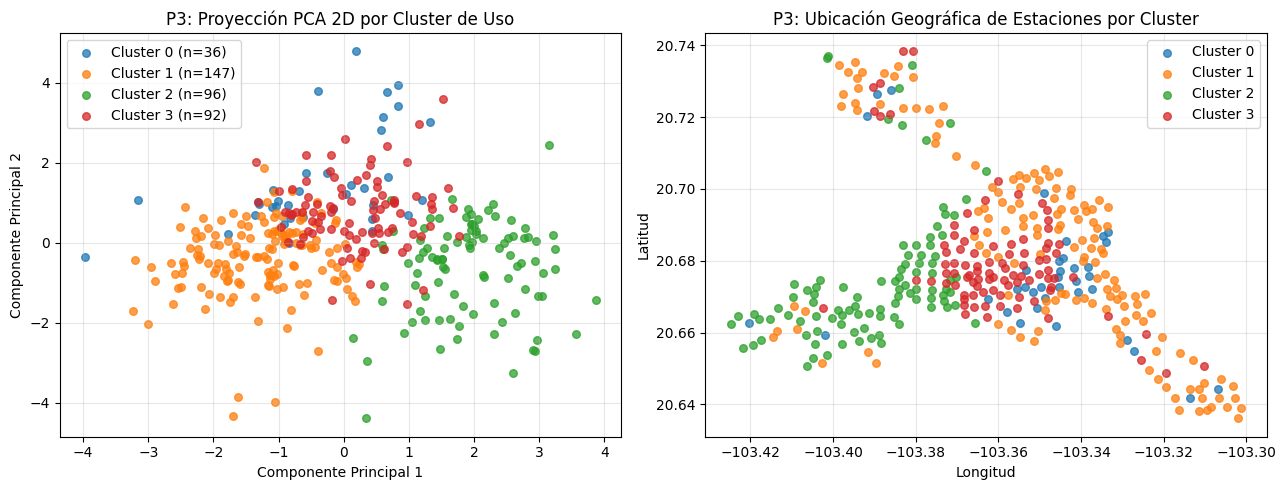

,dep_morning,dep_midday,dep_evening,dep_weekend,median_duration_min,round_trip_pct,avg_daily_trips,dep_arr_ratio
cluster_usage,,,,,,,,
0,0.199,0.284,0.281,0.181,9.897,0.076,24.983,0.932
1,0.298,0.183,0.244,0.213,9.306,0.043,19.506,0.976
2,0.168,0.190,0.382,0.192,12.391,0.031,23.172,1.336
3,0.201,0.215,0.301,0.210,9.205,0.031,67.411,1.028


In [5]:
pca = PCA(n_components=2, random_state=RANDOM_SEED)
coords_2d = pca.fit_transform(X_train_usage)
prof_train['pca_1'] = coords_2d[:, 0]
prof_train['pca_2'] = coords_2d[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for c in sorted(prof_train['cluster_usage'].unique()):
    sub = prof_train[prof_train['cluster_usage'] == c]
    axes[0].scatter(sub['pca_1'], sub['pca_2'], label=f'Cluster {c} (n={len(sub)})', alpha=0.75, s=30)
axes[0].set_title('P3: Proyección PCA 2D por Cluster de Uso')
axes[0].set_xlabel('Componente Principal 1')
axes[0].set_ylabel('Componente Principal 2')
axes[0].legend()
axes[0].grid(alpha=0.3)

for c in sorted(prof_train['cluster_usage'].unique()):
    sub = prof_train[prof_train['cluster_usage'] == c]
    axes[1].scatter(sub['longitude'], sub['latitude'], label=f'Cluster {c}', alpha=0.75, s=30)
axes[1].set_title('P3: Ubicación Geográfica de Estaciones por Cluster')
axes[1].set_xlabel('Longitud')
axes[1].set_ylabel('Latitud')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Resumen de medias por cluster conectado con los 4 grupos de references/ml-canvas.md
cluster_names = {
    0: 'Mixto / Recreativo y universitario',
    1: 'Residencial / Emisor matutino',
    2: 'Laboral / Emisor vespertino de recorridos largos',
    3: 'Nodos centrales de alta rotación',
}
cluster_summary = prof_train.groupby('cluster_usage')[usage_cols].mean().round(3)
cluster_summary['n_stations'] = prof_train.groupby('cluster_usage').size()
cluster_summary['perfil_ml_canvas'] = cluster_summary.index.map(cluster_names)
cluster_summary

### Conclusiones
- `k=4` da la mayor caída relativa de Davies-Bouldin (`-11.94%` desde `k=3`) y separa las 371 estaciones con perfil en `Train` en:
  - **Cluster 0, mixto / recreativo y universitario ($n=36$):** más viajes al mediodía (`28.4%`) y más viajes redondos (`7.6%`).
  - **Cluster 1, residencial / emisor matutino ($n=147$):** `29.8%` de las salidas entre 6 y 10 h.
  - **Cluster 2, laboral / emisor vespertino de recorridos largos ($n=96$):** `38.2%` de las salidas entre 16 y 20 h, duración mediana de `12.39 min` y razón salidas/llegadas de `1.34`.
  - **Cluster 3, nodos centrales de alta rotación ($n=92$):** `67.4` viajes diarios por estación con flujo balanceado (`dep_arr_ratio = 1.03`).
- El clustering por uso separa mejor que el geográfico (Silueta `0.1810` contra `0.0735`, Davies-Bouldin `1.5849` contra `2.7883`) porque estaciones cercanas pueden tener comportamientos opuestos.
- El filtro de 1 a 180 min evita que los `340,142` falsos anclajes sesguen `round_trip_pct` y `median_duration_min`.
- La estabilidad contra 2026 es moderada (ARI ≈ 0.47); conviene revisarla al recalibrar.

Siguiente paso: mover el perfil de uso a `mi_bici/features.py` y registrar los runs en MLflow con el mapa y la proyección PCA como artefacto.